# NumCompute-Assignment 2 demonstration

Sections cover CSV loading, incremental preprocessing, statistics, buffered training, metrics, plots and benchmarks. Small arrays demonstrate preprocessing state changes. Training uses the original CSV.

## 1. Setup and CSV inspection

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if not (project_root / "numcompute").is_dir():
    project_root = project_root.parent
if not (project_root / "numcompute_stream").is_dir():
    raise FileNotFoundError("Open the file from the project root")
sys.path.insert(0, str(project_root))

import numpy as np
from numcompute.io import iter_csv_chunks
from numcompute_stream.preprocessing import StandardScaler, MinMaxScaler, Imputer, OneHotEncoder
from numcompute_stream.stats import StreamStats
from numcompute_stream.metrics import StreamingMetrics, StreamingAUC
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth,
)

np.set_printoptions(precision=3, suppress=True)
csv_path = project_root / "demo" / "sample_data.csv"
print("CSV:", csv_path.name)
for line in csv_path.read_text().splitlines()[:5]:
    print(line)
sizes = [len(c) for c in iter_csv_chunks(csv_path, 30, skip_header=1, usecols=(0, 1, 4))]
print("Chunk sizes:", sizes, "| Total rows:", sum(sizes))

CSV: sample_data.csv
age,income,city,plan,churn
22,53797,London,plus,1
58,48618,London,plus,0
,54128,Paris,basic,1
40,74488,London,pro,0
Chunk sizes: [30, 30, 30, 30, 30, 30, 20] | Total rows: 200


## 2. Incremental preprocessing
Each partial_fit extends learned statistics. Calling fit starts over.

In [2]:
scaler = StandardScaler().partial_fit([[1.0], [3.0]])
scaler.partial_fit([[5.0], [7.0]])
print("Running mean:", scaler.mean_, "| Variance:", scaler.var_)
print("Scaled rows:", scaler.transform([[1.0], [7.0]]).ravel())

minmax = MinMaxScaler().partial_fit([[2.0], [4.0]])
minmax.partial_fit([[0.0], [8.0]])
print("Min-max output:", minmax.transform([[0.0], [4.0], [8.0]]).ravel())

imputer = Imputer(fill_value=-1).partial_fit([[2.0, np.nan]])
imputer.partial_fit([[4.0, 8.0], [6.0, 12.0]])
print("Missing values filled:", imputer.transform([[np.nan, np.nan]]))

encoder = OneHotEncoder(handle_unknown="ignore").partial_fit(["blue", "red"])
print("Initial columns:", encoder.get_feature_names_out())
encoder.partial_fit(["amber"])
print("Expanded columns:", encoder.get_feature_names_out())
print("Encoded amber and red:", encoder.transform(["amber", "red"]))

Running mean: [4.] | Variance: [5.]
Scaled rows: [-1.342  1.342]
Min-max output: [0.  0.5 1. ]
Missing values filled: [[ 4. 10.]]
Initial columns: ['x0_blue', 'x0_red']
Expanded columns: ['x0_amber', 'x0_blue', 'x0_red']
Encoded amber and red: [[1. 0. 0.]
 [0. 0. 1.]]


## 3. Streaming statistics
Process age in chunks with fixed histogram edges from 0 to 100. Exact quantiles retain observations.

In [3]:
age_stats = StreamStats([0, 20, 40, 60, 80, 100])
for chunk in iter_csv_chunks(csv_path, 30, skip_header=1, usecols=(0,)):
    age_stats.update_stats(chunk)

print("Age mean:", age_stats.mean)
print("Age variance:", age_stats.var())
print("Age quartiles:", age_stats.quantile([0.25, 0.5, 0.75]).ravel())
print("Age histogram:", age_stats.histogram())

Age mean: [44.135]
Age variance: [196.311]
Age quartiles: [33. 44. 57.]
Age histogram: [[ 3 65 88 29  0]]


## 4. Streaming training and logs
Age and income predict churn. Predictions precede training on each chunk. Preprocessing and tree updates happens together at retraining boundaries.

In [4]:
def make_trainer(buffer_size):
    return StreamTrainer(Pipeline([
        ("impute", Imputer()),
        ("tree", DecisionTreeClassifier(max_depth=3, buffer_size=buffer_size)),
    ]))

small = make_trainer(30)
large = make_trainer(60)
cumulative = StreamingMetrics()
rolling = StreamingMetrics(window_size=60)
latest_actual = latest_predicted = None

for chunk in iter_csv_chunks(csv_path, chunksize=30, skip_header=1, usecols=(0, 1, 4)):
    X, y = chunk[:, :2], chunk[:, 2]
    if small.pipeline.named_steps["tree"].root_ is not None:
        latest_actual = y.copy()
        latest_predicted = small.pipeline.predict(X)
        cumulative.update(y, latest_predicted)
        rolling.update(y, latest_predicted)
    print(small.fit_chunk(X, y))
    large.fit_chunk(X, y)

{'chunk': 1, 'rows': 30, 'accuracy': None, 'cumulative_accuracy': None, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 2, 'rows': 30, 'accuracy': 0.5666666666666667, 'cumulative_accuracy': 0.5666666666666667, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 3, 'rows': 30, 'accuracy': 0.7, 'cumulative_accuracy': 0.6333333333333333, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 4, 'rows': 30, 'accuracy': 0.6666666666666666, 'cumulative_accuracy': 0.6444444444444445, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 5, 'rows': 30, 'accuracy': 0.7, 'cumulative_accuracy': 0.6583333333333333, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 6, 'rows': 30, 'accuracy': 0.6, 'cumulative_accuracy': 0.6466666666666666, 'chunk_bytes': 720, 'buffer_bytes': 0}
{'chunk': 7, 'rows': 20, 'accuracy': 0.7, 'cumulative_accuracy': 0.6529411764705882, 'chunk_bytes': 480, 'buffer_bytes': 480}


## 5. Cumulative and rolling metrics
These results use the 30-row-buffer model's predictions before training.

In [5]:
for name, metric in [("Cumulative", cumulative), ("Latest 60 scored rows", rolling)]:
    result = metric.result()
    print(name)
    print("Accuracy:", round(float(result["accuracy"]), 3))
    print("Precision:", result["precision"])
    print("Recall:", result["recall"])
    print("F1:", result["f1"])
    print("Confusion matrix (actual rows, predicted columns):")
    print(result["confusion_matrix"])

Cumulative
Accuracy: 0.653
Precision: [0.701 0.613]
Recall: [0.6   0.713]
F1: [0.647 0.659]
Confusion matrix (actual rows, predicted columns):
[[54 36]
 [23 57]]
Latest 60 scored rows
Accuracy: 0.667
Precision: [0.773 0.605]
Recall: [0.531 0.821]
F1: [0.63  0.697]
Confusion matrix (actual rows, predicted columns):
[[17 15]
 [ 5 23]]


### ROC AUC and reset
This example supplies demonstration scores explicitly. The current tree does not provide prediction probabilities. Exact cumulative AUC stores labels and scores.

In [6]:
auc = StreamingAUC().update([0, 0], [0.1, 0.4])
print("AUC with only one class:", auc.result())
auc.update([1, 1], [0.35, 0.8])
print("AUC after both classes arrive:", auc.result())
auc.reset()
print("AUC after reset:", auc.result())

AUC with only one class: nan
AUC after both classes arrive: 0.75
AUC after reset: nan


## 6. Visualisations
The cumulative curves have different warm-up periods. Section 7 scores both models on the same 140 rows.

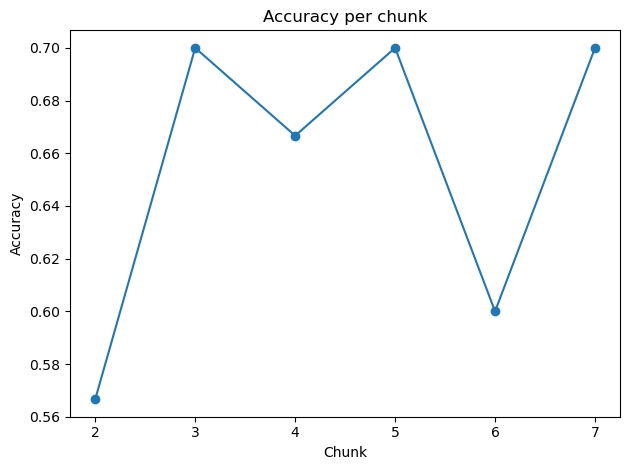

In [7]:
plot_metric_over_time(
    [entry["accuracy"] for entry in small.history],"Accuracy per chunk","Accuracy",);

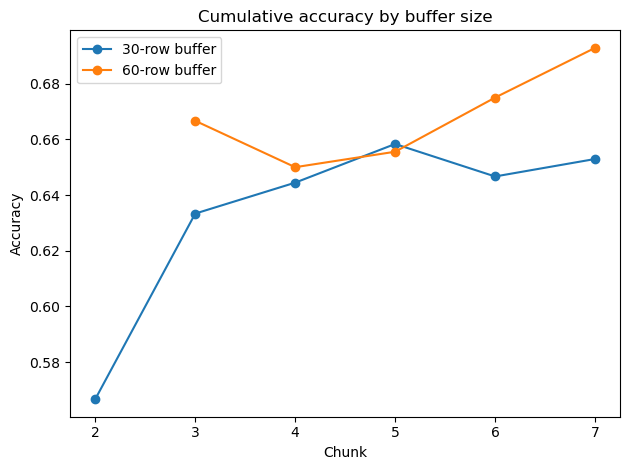

In [8]:
compare_models(
    [entry["cumulative_accuracy"] for entry in small.history],
    [entry["cumulative_accuracy"] for entry in large.history],
    labels=("30-row buffer", "60-row buffer"),);

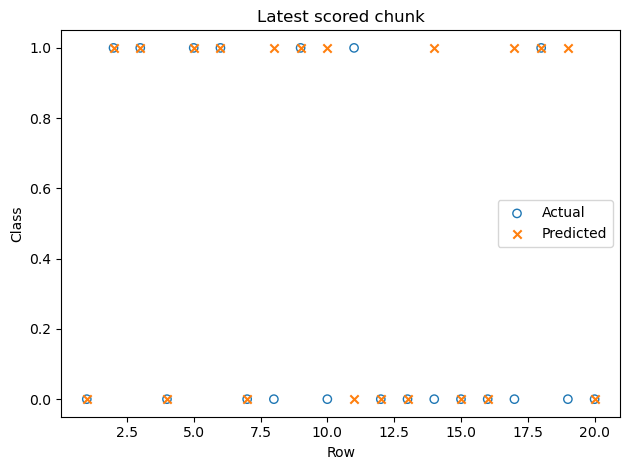

In [9]:
plot_predictions_vs_ground_truth(latest_actual, latest_predicted);

## 7. Streaming benchmarks
Loop and NumPy results must match. Both buffers use the same evaluation rows. Timings may vary by machine and run.

In [10]:
from benchmark.run_stream_benchmarks import benchmark_confusion_matrix, benchmark_buffer_sizes
benchmark_confusion_matrix()
benchmark_buffer_sizes()

Python loop: 13.96 ms
NumPy updates: 9.86 ms
Buffer 30: 67.1% accuracy on 140 rows, 6 retrains, 1.29 ms per retraining update
Buffer 60: 69.3% accuracy on 140 rows, 3 retrains, 1.76 ms per retraining update
